# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as ny

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:

# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)


plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [8]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [9]:
# cantidad de nulos para users
print(users.isna().sum())
print(users.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [10]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**. Que una columna tenga este porcentaje de valores nulos no necesariamente implica que deba eliminarse. Podríamos considerar la columna churn_date. Esta columna puede hacer referencia a la fecha de retiro de usuarios o cancelación de los planes, este valor cuenta con una alta cantidad de valores "nulos o vacíos". Esto no necesariamente es un error, pero eliminarla podría quitarnos la posibilidad de analizar, ¿qué tipo de usuarios son los que se han retirado? ¿cuál era su perfil de consumo? ¿cuál es el tipo de plan que más retiro presenta?  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**. Estoy de acuerdo con investigar para imputar o dejar nulos.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. Este caso es más fácil de resolver dado que este porcentaje puede no ser tan sensible al momento de las imputaciones.

Como analistas de datos debemos entender que un campo nulo o vacío también puede ser información de valor y arrojar información del modelo de negocio. Como regla general, siento que es más conveniente antes de cualquier imputación hacer una investigación para entender el origen del comportamiento de los datos y a su vez tomar decisiones.
 
 ---

**Valores nulos**  

- Indica qué harías: ¿imputar, eliminar, ignorar?
  
Para el análisis de datos de la empresa ConnectaTel se tiene un conjunto de datos de 3 tablas organizados de la siguiente manera:

**Tabla plans** tiene 8 columnas: 
- plan_name de tipo object / messages_included de tipo int64 / gb_per_month de tipo int64 / minutes_included de tipo int64 / usd_monthly_pay de tipo int64 / usd_per_gb de tipo float64 / usd_per_message de tipo float64 / usd_per_minute de tipo float64

El número total de registros de la tabla es de 2 filas y ninguna columna presenta valores nulos. No requiere tomar acciones.

**Tabla users** tiene 8 columnas: 
- user_id de tipo int64 / first_name de tipo object / last_name de tipo object / age de tipo int64 / city de tipo object / reg_date de tipo object / plan de tipo object / churn_date de tipo object.

El número total de registros de la tabla es de 4.000 filas, pero la columna city tiene 469 valores nulos, equivalentes al 11,73% de datos faltantes. Esta columna se puede mantener como dato desconocido para no eliminar registros. 

Mientras que la columna churn_date tiene 3.534 valores nulos, equivalentes al 88,35% de datos faltantes. Podemos concluir que esto no es un error en la recolección de los datos, porque la columna churn_date corresponde a la fecha de cancelación de los planes, es decir, que del 100% de los datos, que el 88,35% esté nulo podría significar que son usuarios activos.


**Tabla usage** tiene 6 columnas: 
- id de tipo int64 / user_id de tipo int64 / type de tipo object / date de tipo object / duration de tipo float64 / length de tipo float64

El número total de registros de la tabla es de 40.000 filas, pero la columna date tiene 50 valores nulos, equivalentes al 0,125% de datos faltantes. Considero que este valor es muy bajo para hacer ruido en los datos, se tomarán como datos vacíos.

La columna duration tiene 22.076 valores nulos, equivalentes al 55,19% de datos faltantes; y la columna length tiene 17.896 valores nulos, equivalentes al 44,74% de datos faltantes. Dado que el porcentaje de valores nulos es muy alto tanto para la columna duration como para length, eliminar estos registros puede eliminar información necesaria de las otras columnas. También es conveniente considerar que cada columna mide cosas diferentes, es decir, que un usuario puede tener un cierto flujo de llamadas pero no hacer uso de los mensajes, y al revés. La columna usage está agrupando 2 medidas diferentes en una misma tabla, lo cual, al momento de visualizar los datos puede percibirse como error. En este caso también es conveniente usar un sentinel para dejar esos valores como vacíos.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [11]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


In [12]:

# explorar cuántos registros únicos tiene la columna user_id
# para determinar si es un identificador único de los usuarios
# o es un dato numérico con el cual realizar cálculos
print(len(users['user_id'].unique()))


4000


- La columna `user_id` tiene un total de 4000 registros de los cuales su totalidad son valores únicos. Esto evidencia que no es un valor numérico con el cual operar, sino un identificador único de cada usuario que corresponde a la clave primaria de la tabla users, lo cual no nos aporta información dentro de esta tabla para realizar cálculos estadísticos. 
- La columna `age` es una variable numérica cuyo valor mínimo es -999, este es un valor anómalo que puede ser considerado un sentinel usado para representar un dato desconocido o incorrecto. Además, la media de 33,74 años es inferior a la mediana de 47 años, posiblemente debido a ese valor extremo. Serán remplazados por NaN, sin imputar una edad hasta contar con una fuente confiable. 

In [13]:

# explorar columnas numéricas de usage
usage.describe()


,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` son Variables Categóricas Nominales (Códigos o Identificadores). Son números que funcionan puramente como etiquetas, identificadores o nombres. La columna `id` tiene un total de registros de 1 a 40000, que es la totalidad de registros de la tabla, esto quiere decir que es un número secuencial cuya función es ser un identificador único para la tabla, es decir que es la clave primaria de la tabla usage. Adicional, `user_id` es la clave foránea que conecta la tabla usage con la tabla users. Se puede evaluar la aparición de un user_id repetido para determinar la ocurrencia de eventos asociados a un mismo usuario, pero no se puede operar como una variable numérica normal. 
- La columna `duration` tiene un valor mínimo de 0 y uno máximo de 120. Una duración de 0 podría corresponder a una llamada no conectada. Adicional, el valor máximo es un valor lejano respecto a la mediana y la media que son de 3.5 y 5.2 respectivamente.
- Para la columna `length` el valor mínimo 0 y la máxima es 1.490. El valor máximo es muy superior a la mediana de 50, lo que sugiere un valor atípico. Es necesario revisarlo con detalle. 
- Tanto la columna `duration` como la columna `length` requieren una revisión de datos atípicos por medio del método IQR.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(f'\nValores únicos de users[{col}]:')
    print(users[col].value_counts(dropna=False))


Valores únicos de users[city]:
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores únicos de users[plan]:
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city` tiene 8 variables entre las cuales se identifican 6 ciudades diferentes, 469 valores desconocidos "NaN" y 1 variable sentinel "?" con 96 registros. Se imputará la variable "?" por "NaN"
- La columna `plan` tiene 2 variables "Basico" y "Premium" sin varoles inválidos.

In [15]:

# explorar columna categórica de usage
# completa el código
for col in ['type'] :
    print(f'\nValores únicos de usage[{col}]:')
    print(usage[col].value_counts(dropna=False))



Valores únicos de usage[type]:
text    22092
call    17908
Name: type, dtype: int64


- La columna `type` tiene 2 variables: "text" y "call" sin valores inválidos.

---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?

En el dataset users, la columna age presenta un valor mínimo de -999, que se considera un sentinel o valor inválido. Se reemplazará por NaN.

En el dataset usage, las columnas duration y length presentan valores máximos de 120 y 1.490, respectivamente. Estos valores podrían representar observaciones atípicas, por lo que se gestionarán mediante el método IQR.

En las variables categóricas, la columna city contiene 96 registros con el símbolo ?. Se estandizará con los valores nulos reemplazando "?" por NaN, conservando los registros originales. La columna plan presenta únicamente las categorías Básico y Premium, mientras que type contiene los valores esperados call y text.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(
    users['reg_date'],
    errors='coerce'
)

In [17]:

# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(
    usage['date'],
    errors='coerce'
)

In [18]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts().sort_index())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


In [19]:
# Revisar valores nulos después de realizar la conversión de la fecha
print("Nulos en reg_date:", users['reg_date'].isna().sum())

Nulos en reg_date: 0


En `reg_date`, se identificaron registros entre 2022 y 2026, no se generaron valores nulos en la conversión.

In [20]:

# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts().sort_index())

2024.0    39950
Name: date, dtype: int64


In [21]:
# Revisar valores nulos después de realizar la conversión de la fecha
print("Nulos en date:", usage['date'].isna().sum())

Nulos en date: 50


En `date`, podemos validar que el total de los registros corresponden al año 2024, que corresponde al año objetivo para este análisis. También vemos que no se agregaron valores nulos adicionales a los 50 que se tenían de la data original.

Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
  No aparecen años imposibles.
- ¿Qué harías con ellas?
  Solo es necesario darle manejo a los 50 registros de la columna date de la tabla usage.

---
## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [22]:

# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [23]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].isna().sum()

565

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
- Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [24]:
# Verificación MAR en usage (Missing At Random) para duration
usage.groupby('type')['duration'].agg(
    total='count',
    valores_nulos=lambda x: x.isna().sum()
)

,total,valores_nulos
type,,
call,17908,0.0
text,16,22076.0


Se realiza un filtrado por la columna 'duration' para determinar si hay relación con la columna 'type'. Cuando el tipo es call, la duración tiene todos sus registros válidos (0 nulos) y la longitud de los mensajes es 100% nula. Adicional se presenta un comportamiento inesperado, de los 17908 registros de tipo llamadas(call), 16 presentan un valor asociado en la columna 'length'.

In [25]:
# Verificación MAR en usage (Missing At Random) para length
usage.groupby('type')['length'].agg(
    total='count',
    valores_nulos=lambda x: x.isna().sum()
)

,total,valores_nulos
type,,
call,12,17896.0
text,22092,0.0


Se realiza filtrado por la columna 'length'. Cuando el tipo es text, la longitud tiene todos sus registros válidos (0 nulos) y la duración es 100% nula. Sin embargo, también se evidencia que de los 22092 registros de tipo texto(text), 12 presentan un valor asociado en la columna 'duration'

Podemos confirmar que los valores nulos para las columnas 'duration' y 'length' son MAR. Su ausencia está relacionada con la columna de tipo 'type'. Cuando el tipo es 'call', la cual está relacionada con las llamadas, la información se registra en la columna 'duration', por lo cual no hay un valor asociado en la columna 'length', que está relacionada con los datos de tipo 'text' y que corresponde a la longitud de los mensajes. Y el patron se invierte cuando la variable es de tipo 'text'.

Se trata de datos faltantes por diseño estructural. Los nulos no se deben a errores de medición ni a pérdida de información aleatoria, sino a la naturaleza combinada de la tabla 'usage', donde coexisten dos eventos de telecomunicaciones totalmente distintos. Por lo tanto, se deben dejar como 'NaN' sin imputar ningún valor (como ceros o medias), ya que cualquier alteración distorsionaría las métricas reales de llamadas y mensajes al calcular promedios o distribuciones.

Sin embargo, es necesario analizar los comportamientos inespereados enunciados en las 2 consultas previas:  # Mensajes (text) que tienen duration registrado y # Llamadas (call) que tienen length registrado

In [26]:
# Mensajes (text) que tienen duration registrado
text_con_duration = usage[
    (usage['type'] == 'text') &
    (usage['duration'].notna())
]

print(text_con_duration)

          id  user_id  type                          date  duration  length
1414    1415    10399  text 2024-01-07 09:33:51.260781519     120.0    65.0
1824    1825    12936  text 2024-01-09 06:05:28.868221705     120.0    40.0
1932    1933    10189  text 2024-01-09 17:49:13.603840096     120.0    69.0
2972    2973    10085  text 2024-01-14 10:46:02.169054226     120.0    68.0
11456  11457    13325  text 2024-02-21 20:09:09.733743343     120.0    23.0
16702  16703    10484  text 2024-03-16 13:52:57.169429235     120.0    48.0
22814  22815    12711  text 2024-04-13 05:39:44.429610740     120.0    70.0
23052  23053    13850  text 2024-04-14 07:30:35.235880896     120.0    24.0
23451  23452    13265  text 2024-04-16 02:50:32.175804394     120.0    53.0
26561  26562    13920  text 2024-04-30 04:35:48.173704342     120.0    89.0
27171  27172    12786  text 2024-05-02 22:50:39.735993400     120.0    44.0
28921  28922    10372  text 2024-05-10 20:53:56.840921022     120.0    53.0
36587  36588

Podemos notar un patrón sospechoso en los datos: La variable es de tipo texto, en los cuales los registros para la columna 'length' presentan variabilidad en los datos, la columna duration presenta el mismo valaor, como si correspondiera a un error de registro.

In [27]:
# Llamadas (call) que tienen length registrado
call_con_length = usage[
    (usage['type'] == 'call') &
    (usage['length'].notna())
]

print(call_con_length)

          id  user_id  type                          date  duration  length
2070    2071    13139  call 2024-01-10 08:48:27.432685817      1.68  1490.0
5272    5273    11750  call 2024-01-24 20:33:12.649816245      3.78  1490.0
10614  10615    13855  call 2024-02-18 00:42:33.183829595      0.53  1490.0
12692  12693    12263  call 2024-02-27 10:23:08.374709367      1.80  1490.0
16910  16911    12099  call 2024-03-17 12:28:18.882472061      3.29  1490.0
20727  20728    10599  call 2024-04-03 19:00:30.510762768      0.40  1490.0
20778  20779    11401  call 2024-04-04 00:32:49.969249231      1.01  1490.0
25444  25445    10781  call 2024-04-25 03:17:14.935873396      3.57  1490.0
26057  26058    11018  call 2024-04-27 21:51:39.407485186      0.63  1490.0
26506  26507    12400  call 2024-04-29 22:37:24.836120902      1.12  1490.0
26587  26588    11241  call 2024-04-30 07:25:13.387834696      1.03  1490.0
37981  37982    13579  call 2024-06-20 20:50:22.995574888      0.93  1490.0


En este caso, al realizar el filtrado para los registro de tipo 'call' (llamada), podemos identificar variabilidad en la columna 'duration', mientras que la columna 'length' tiene un valor estático, como si fuera un error de registro. Para esta consulta se invierte el patrón de la consulta anterior. 

Durante la revisión de patrones inesperados se identificaron 16 registros de mensajes (text) con una duración de 120 minutos y 12 registros de llamadas (call) con una longitud de 1490. Es este caso se procede a imputar los valores como nulos.

In [28]:
# Marcar length como nulo para las llamadas
usage.loc[usage['type'] == 'call', 'length'] = usage.loc[
    usage['type'] == 'call', 'length'
].where(usage['length'].isna())

# Llamadas (call) que tienen length registrado para comprobar que se corrigió
call_con_length = usage[
    (usage['type'] == 'call') &
    (usage['length'].notna())
]

print(call_con_length)

Empty DataFrame
Columns: [id, user_id, type, date, duration, length]
Index: []


In [29]:
# Marcar duration como nulo para los mensajes
usage.loc[usage['type'] == 'text', 'duration'] = usage.loc[
    usage['type'] == 'text', 'duration'
].where(usage['duration'].isna())

# Mensajes (text) que tienen duration registrado
text_con_duration = usage[
    (usage['type'] == 'text') &
    (usage['duration'].notna())
]

print(text_con_duration)

Empty DataFrame
Columns: [id, user_id, type, date, duration, length]
Index: []


In [30]:
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17908.000000,22092.000000
mean,20000.50000,12002.405975,5.099671,51.346370
std,11547.14972,1157.279564,5.922735,45.638659
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.430000,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.970000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


Después de corregir los valores inconsistentes de las variables duration y length, se identificaron 16 registros de mensajes con duración registrada y 12 registros de llamadas con longitud registrada. Estos valores fueron marcados como nulos, conservando los 40.000 registros originales.

Como resultado, la cantidad de valores válidos en duration pasó de 17.924 a 17.908, mientras que en length pasó de 22.104 a 22.092. Un comportamiento esperado es que también disminuyeron sus medias y desviaciones estándar, lo que refleja una reducción de la influencia de los valores inconsistentes sobre las estadísticas descriptivas.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [31]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [32]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [33]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users, usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 5.4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [34]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
resumen_num = user_profile[columnas_numericas].describe()
display(resumen_num)

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,22.836934
std,17.689919,2.358416,2.144238,16.590213
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.095000
50%,48.000000,5.000000,4.000000,19.740000
75%,63.000000,7.000000,6.000000,31.185000
max,79.000000,17.000000,15.000000,155.690000


In [35]:
# Distribución porcentual del tipo de plan
distribucion_plan = user_profile['plan'].value_counts(normalize=True) * 100
print("\nDistribución porcentual de planes:")
print(distribucion_plan)


Distribución porcentual de planes:
Basico     64.875
Premium    35.125
Name: plan, dtype: float64


La edad promedio es de 48, con una cantidad 

---


## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

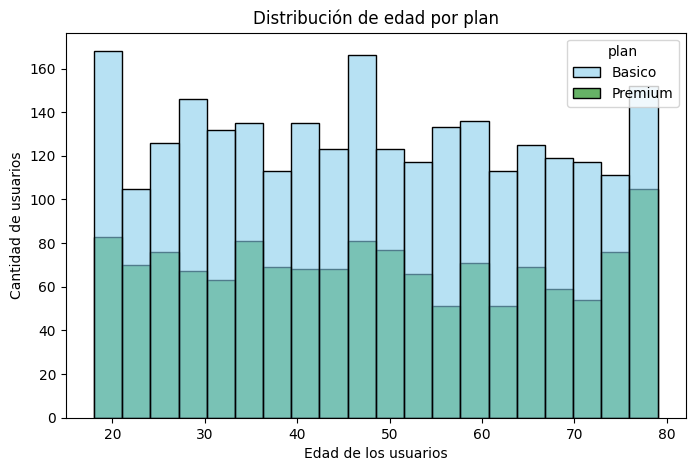

In [36]:
# Histograma para visualizar la edad (age)
plt.figure(figsize=(8, 5))
sns.histplot(
    data= user_profile,
    x = 'age',
    hue = 'plan',
    palette=['skyblue', 'green'],
    bins=20,
    alpha=0.6
)
plt.title('Distribución de edad por plan')
plt.xlabel('Edad de los usuarios')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- Esta gráfica presenta un comportamiento relativamente homogéneo, aunque se identifican algunas concentraciones en determinados intervalos. No se observa una distribución claramente simétrica ni un sesgo pronunciado hacia edades jóvenes o mayores.

- Para ambos planes existe una mayor cantidad de usuarios del plan Básico en todos los rangos de edad, lo cual tiene relación con su mayor participación dentro de la base general de clientes (64.875%).

- El plan Básico presenta picos alrededor de los 20 y 48 años, mientras que el plan Premium alcanza su mayor frecuencia en el intervalo aproximado de 77 a 79 años.

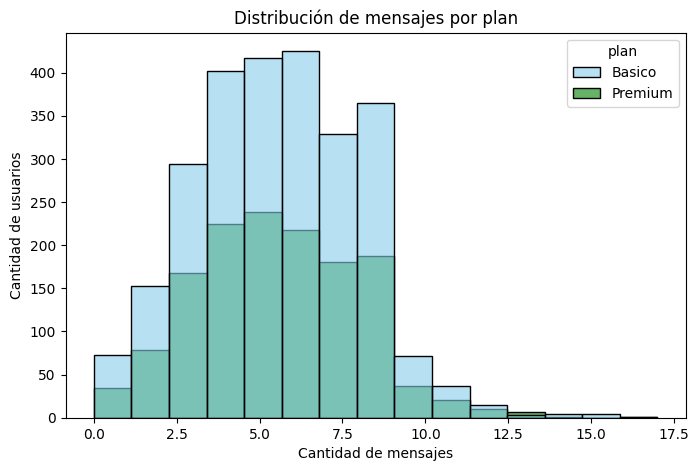

In [37]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8, 5))
sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15,
    alpha=0.6
)
plt.title('Distribución de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights: 
- La gráfica de la cantidad de mensajes presenta un comportamiento donde ambos planes presentan un pico y tienen caída hacia la derecha. La frecuencia de usuarios aumenta progresivamente entre 0 y aproximadamente 6 mensajes, donde alcanza su mayor concentración. Posteriormente, disminuye y forma una cola hacia los valores más altos, llegando hasta aproximadamente 17 mensajes.
- Al comparar los planes, se observa que los usuarios Básico representan una mayor cantidad de clientes en prácticamente todos los intervalos, con una concentración importante entre 5 y 7 mensajes. Los usuarios Premium presentan un comportamiento similar, con su mayor concentración alrededor de 5 y 6 mensajes.

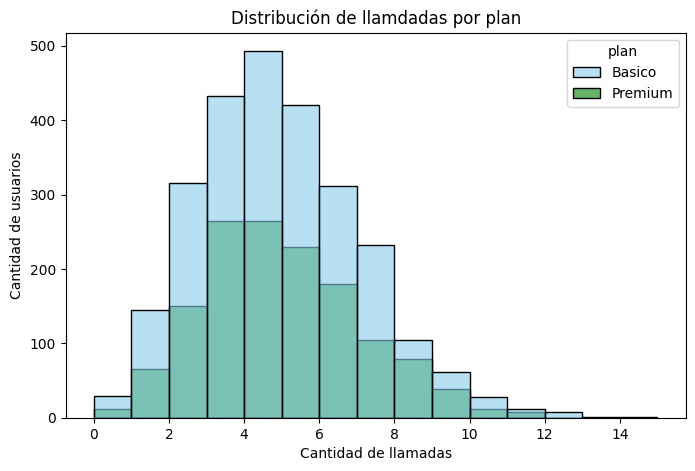

In [38]:
# Histograma para visualizar la cant_llamadas

plt.figure(figsize=(8, 5))
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15,
    alpha=0.6
)
plt.title('Distribución de llamdadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights: 
- En la gráfica de la cantidad de llamdas por plan, ambos planes presentan un pico y tienen caída hacia la derecha. La frecuencia de usuarios aumenta progresivamente entre 0 y aproximadamente 5 llamadas, donde alcanza su mayor concentración. Posteriormente, disminuye y forma una cola hacia los valores más altos, llegando hasta aproximadamente 15 llamadas.
- Al comparar los planes, se observa que los usuarios Básico representan una mayor cantidad de clientes en prácticamente todos los intervalos, con una concentración importante entre 3 y 6 llamadas, con el pico más alto en 5 llamadas. Los usuarios Premium presentan un comportamiento similar, con su mayor concentración alrededor de 3 y 5 llamadas.

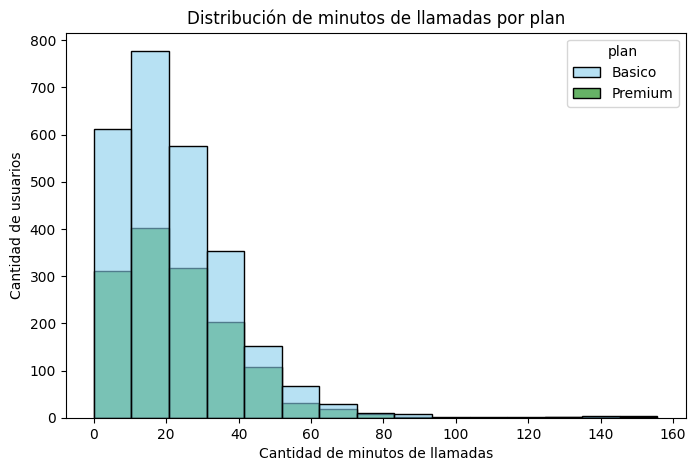

In [39]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 5))
sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green'],
    bins=15,
    alpha=0.6
)
plt.title('Distribución de minutos de llamadas por plan')
plt.xlabel('Cantidad de minutos de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights: 
- En la gráfica de la cantidad de llamdas presenta ambos planes presentan también un pico y tienen caída hacia la derecha. La mayor concentración de usuarios se encuentra aproximadamente entre los 10 y 20 minutos acumulados, donde se alcanza el punto máximo de frecuencia. A partir de allí, la cantidad de usuarios disminuye progresivamente a medida que aumentan los minutos, formando una cola hacia la derecha que se extiende hasta aproximadamente los 90 minutos, con algunos valores aislados superiores.
- Al comparar ambos planes, se observa que los usuarios Básico presentan una mayor frecuencia en prácticamente todos los intervalos, especialmente entre los 10 y 20 minutos. Los usuarios Premium presentan un comportamiento similar en el mismo intervalor.

💡Insights Generales.    
- En la gráfica de distribución de edad por plan, se observa que las edades de los usuarios de ambos planes presentan una distribución relativamente uniforme a lo largo del rango analizado, aproximadamente entre los 18 y 79 años. Esto significa que no existe una concentración claramente dominante en un único intervalo de edad, sino que los usuarios se encuentran distribuidos en diferentes rangos etarios.
- Para las demás gráficas (# Histograma para visualizar la cant_mensajes, # Histograma para visualizar la cant_llamadas y # Histograma para visualizar la cant_minutos_llamada) se evidencia una distribución unimodal asimétricas hacia la derech.  

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>
- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.


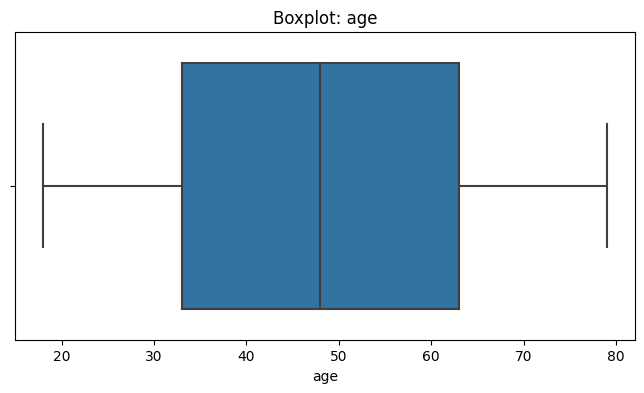

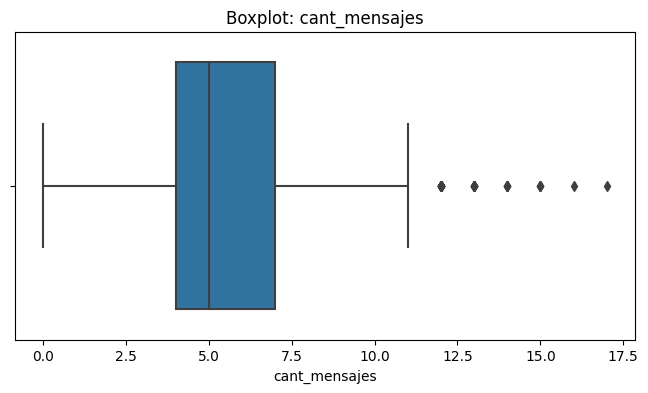

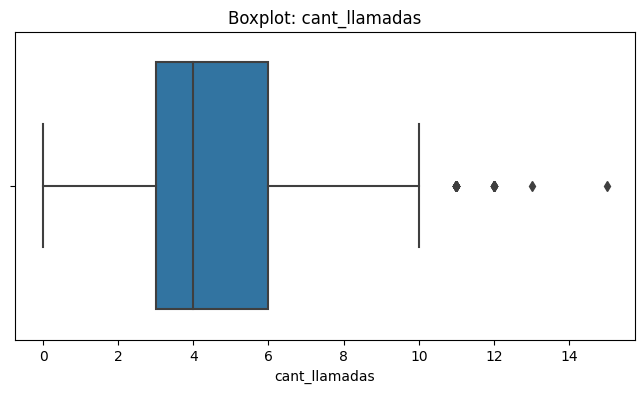

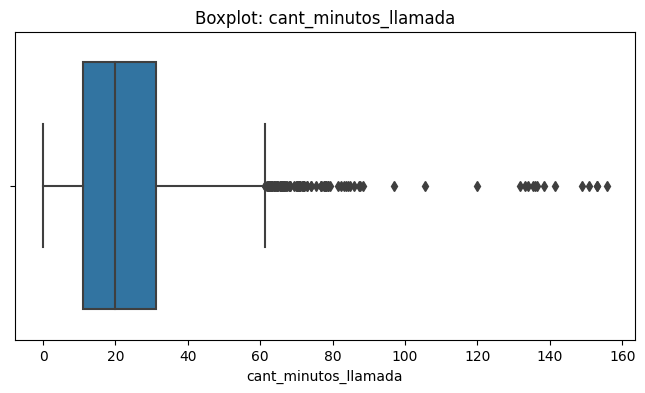

In [40]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Ninguna de las columnas presenta valores atípicos en su límite inferior
- Age: No presenta outliers
- cant_mensajes:  Presenta outliers por encima del extremo superior que tiene un valor aproximado de 11 
- cant_llamadas: Presenta outliers por encima del extremo superior que tiene un valor aproximado de 10
- cant_minutos_llamada: Presenta outliers por encima del extremo superior que tiene un valor aproximado de 60

In [41]:
# Calcular límites con el método IQR
columnas_limites = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)

    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR
    valor_maximo = user_profile[col].max()

    print(f'\nVariable: {col}')
    print(f'Límite superior: {limite_superior:.2f}')
    print(f'Valor máximo: {valor_maximo:.2f}')



Variable: age
Límite superior: 108.00
Valor máximo: 79.00

Variable: cant_mensajes
Límite superior: 11.50
Valor máximo: 17.00

Variable: cant_llamadas
Límite superior: 10.50
Valor máximo: 15.00

Variable: cant_minutos_llamada
Límite superior: 61.32
Valor máximo: 155.69


In [42]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,22.836934
std,17.689919,2.358416,2.144238,16.590213
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.095000
50%,48.000000,5.000000,4.000000,19.740000
75%,63.000000,7.000000,6.000000,31.185000
max,79.000000,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
  El límite superior es de 11.5, frente a un máximo de 17.
- cant_llamadas: mantener o no outliers, porqué?
  El límite superior es de 10.5, frente a un máximo de 15.
- cant_minutos_llamada: mantener o no outliers, porqué?
  El límite superior de 61.32, frente a un máximo de 155.69. Esta es la columna con un outlier más significativo.

Considerando que ConnectaTel quiere analizar el comportamiento de los usuarios para identificar patrones de uso y comprender sus necesidades diferenciadas, los outliers son necesarios para diferenciar ese segmento poblacional que tiene patrones de consumo diferentes e incluir-proponer estrategias que también los incluyan en las estrategias comerciales de ser necesario. Motivo por el cual, considero que no se deben eliminar sino analizarlos con más profundidad.

Me interesa saber cuántos de los usuarios se encuentran en esos valores por fuera del límite superior.

In [43]:
for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)

    IQR = Q3 - Q1
    limite_superior = Q3 + 1.5 * IQR

    # Identificar outliers
    outliers = user_profile[col] > limite_superior

    # Calcular cantidad y porcentaje
    cantidad_outliers = outliers.sum()
    total_usuarios = user_profile[col].notna().sum()
    porcentaje_outliers = (cantidad_outliers / total_usuarios) * 100

    print(f'\nVariable: {col}')
    print(f'Límite superior: {limite_superior:.2f}')
    print(f'Cantidad de outliers: {cantidad_outliers}')
    print(f'Porcentaje de outliers: {porcentaje_outliers:.2f}%')


Variable: age
Límite superior: 108.00
Cantidad de outliers: 0
Porcentaje de outliers: 0.00%

Variable: cant_mensajes
Límite superior: 11.50
Cantidad de outliers: 46
Porcentaje de outliers: 1.15%

Variable: cant_llamadas
Límite superior: 10.50
Cantidad de outliers: 30
Porcentaje de outliers: 0.75%

Variable: cant_minutos_llamada
Límite superior: 61.32
Cantidad de outliers: 96
Porcentaje de outliers: 2.40%


Se concluye que el porcentaje de outliers es muy bajo, sin embargo, corresponden a medidas que pueden reflejar el comportamiento de uso de los planes de los usuarios de ConnectaTel. Se tienen identificados para posibles análisis posteriores, si es requerido por la empresa, de momento no serán eliminados. 

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos


In [44]:

# Crear columna grupo_uso

user_profile['grupo_uso'] = pd.NA

# Condición: Bajo uso
condicion_bajo = (
    (user_profile['cant_llamadas'] < 5) &
    (user_profile['cant_mensajes'] < 5)
)

# Condición: Uso medio
condicion_medio = (
    (user_profile['cant_llamadas'] < 10) &
    (user_profile['cant_mensajes'] < 10)
)

# Asignar categorías
user_profile.loc[condicion_bajo, 'grupo_uso'] = 'Bajo uso'

user_profile.loc[
    condicion_medio & ~condicion_bajo,
    'grupo_uso'
] = 'Uso medio'

user_profile.loc[
    ~condicion_medio,
    'grupo_uso'
] = 'Alto uso'


In [45]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


In [46]:
user_profile['grupo_uso'].value_counts(dropna=False)

Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64

In [47]:
user_profile['grupo_uso'].value_counts(normalize=True) * 100

Uso medio    73.575
Bajo uso     19.450
Alto uso      6.975
Name: grupo_uso, dtype: float64

2943 usuarios que corresponden al 73.57% se clasifican en un uso medio, seguidos de 778 usuarios  que corresponden al 19.45% y 279 usuarios que corresponden solo al 6.97% tienen un uso alto del plan.

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [48]:
# Crear columna grupo_edad

user_profile['grupo_edad'] = pd.NA

# Condición: Bajo uso
condicion_bajo = (
    (user_profile['age'] < 30)
)

# Condición: Uso medio
condicion_medio = (
    (user_profile['age'] < 60) 
)

# Asignar categorías
user_profile.loc[condicion_bajo, 'grupo_edad'] = 'Joven'

user_profile.loc[
    condicion_medio & ~condicion_bajo,
    'grupo_edad'
] = 'Adulto'

user_profile.loc[
    ~condicion_medio,
    'grupo_edad'
] = 'Adulto mayor'

In [49]:
# verificar cambios
user_profile.head()



,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

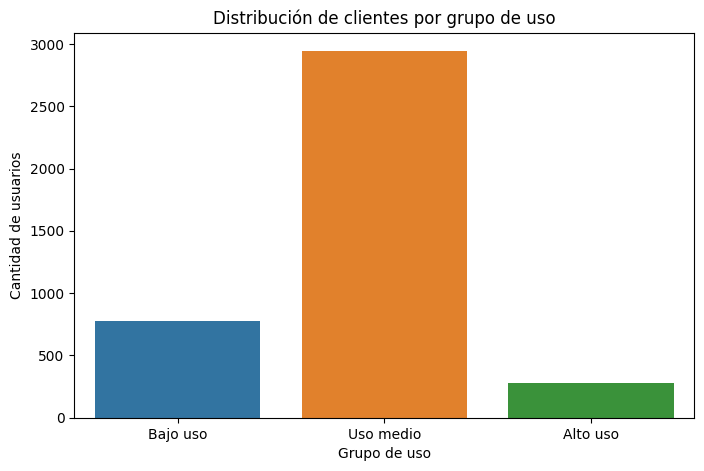

In [50]:
# Visualización de los segmentos por uso

plt.figure(figsize=(8, 5))

sns.countplot(
    data=user_profile,
    x='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso']
)

plt.title('Distribución de clientes por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')

plt.show()

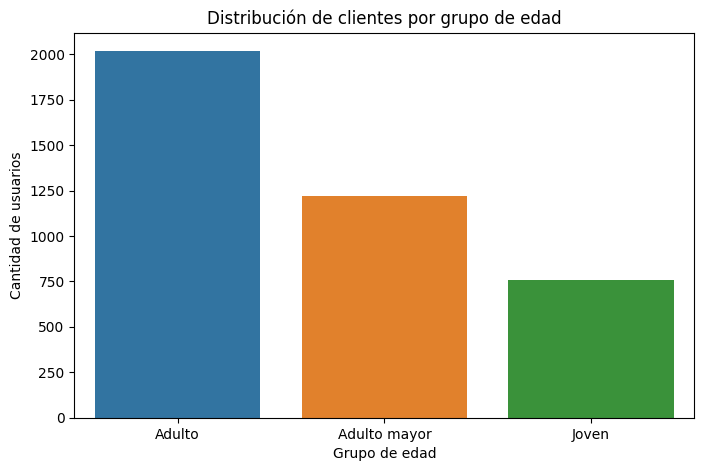

In [100]:
# Visualización de los segmentos por edad

plt.figure(figsize=(8, 5))

sns.countplot(
    data=user_profile,
    x='grupo_edad'
)

plt.title('Distribución de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')

plt.show()

**Gráficas para ver la distribición porcentual de los segmentos:**

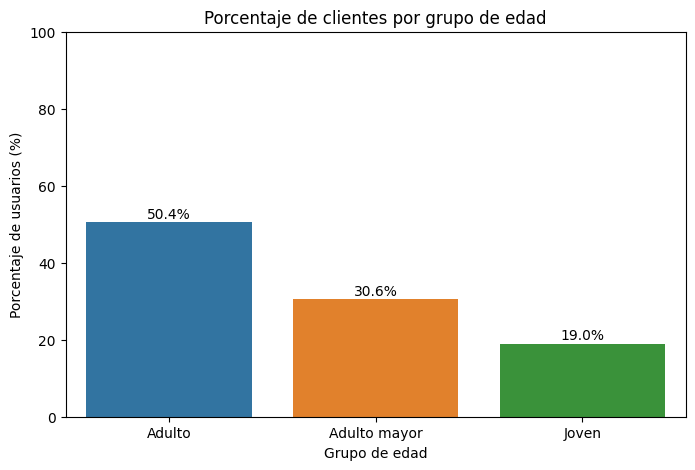

In [52]:
# Porcentaje de clientes por grupo de edad
porcentaje_edad = user_profile['grupo_edad'].value_counts(normalize=True) * 100

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=porcentaje_edad.index,
    y=porcentaje_edad.values
)

plt.title('Porcentaje de clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Porcentaje de usuarios (%)')
plt.ylim(0, 100)

# Agregar porcentajes encima de las barras
for i, valor in enumerate(porcentaje_edad.values):
    ax.text(i, valor + 1, f'{valor:.1f}%', ha='center')

plt.show()


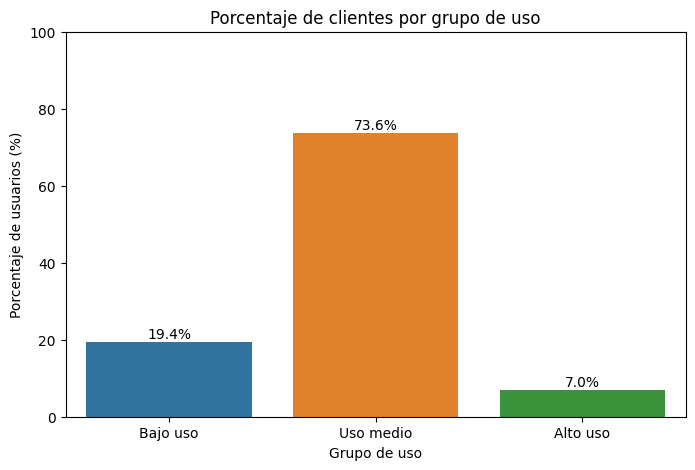

In [53]:
# Porcentaje de clientes por grupo de uso
porcentaje_uso = user_profile['grupo_uso'].value_counts(normalize=True) * 100

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=porcentaje_uso.index,
    y=porcentaje_uso.values,
    order=['Bajo uso', 'Uso medio', 'Alto uso']
)

plt.title('Porcentaje de clientes por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Porcentaje de usuarios (%)')
plt.ylim(0, 100)

# Agregar porcentajes encima de las barras
for i, categoria in enumerate(['Bajo uso', 'Uso medio', 'Alto uso']):
    if categoria in porcentaje_uso.index:
        valor = porcentaje_uso[categoria]
        ax.text(i, valor + 1, f'{valor:.1f}%', ha='center')

plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?


✍️ **Escribe aquí tu análisis ejecutivo:**


### Análisis ejecutivo

El análisis permitió identificar que ConnectaTel tiene una base de clientes concentrada principalmente en el grupo de edad Adulto y en el segmento de Uso medio. Esto representa una oportunidad para fortalecer la oferta actual, mejorar la experiencia de los clientes y diseñar estrategias comerciales orientadas a sus necesidades reales.

Los usuarios de Alto uso merecen atención por su potencial de generar ingresos adicionales, mientras que los de Bajo uso pueden ser abordados mediante estrategias de fidelización y ofertas más ajustadas a su consumo.

Finalmente, la detección de valores atípicos, especialmente en los minutos de llamadas, permite identificar clientes cuyo comportamiento se diferencia del promedio y que podrían beneficiarse de planes personalizados. Se recomienda complementar estos resultados con un análisis de consumo por plan, facturación y cancelaciones antes de tomar decisiones definitivas sobre precios, rentabilidad o migraciones.

⚠️ **Problemas detectados en los datos**

Durante la exploración y limpieza se identificaron valores nulos, registros sentinela y datos que no correspondían al tipo de evento registrado.

Tabla users:

- city: tenía 469 valores nulos y 96 registros con el valor sentinela "?". Estos últimos se reemplazaron por NaN, dejando un total de 565 registros sin ciudad identificada, equivalentes al 14,13 % de los 4.000 usuarios. Se conservaron para no perder información de esos clientes.
- age: se encontró un registro sentinela de -999. Este valor distorsionaba las estadísticas: la media inicial era de 33,74 años, mientras que la mediana era de 47. Fue remplazado por la mediana. Después de la corrección, la media quedó en 48,14 años y la mediana en 48.
- churn_date: presentaba 3.534 valores nulos, equivalentes al 88,35 %. Estos valores pueden corresponder a clientes que no han cancelado el servicio, por lo que no se consideraron errores y se conservaron. 
- reg_date: se encontraron 40 fechas posteriores al periodo de análisis, equivalentes al 1 % de los usuarios. Se marcaron como nulas siguiendo las instrucciones de limpieza. Esta columna corresponde a la fecha de registro del cliente; el análisis de actividad de 2024 se realizó tomando como referencia la columna date de usage.

Tabla usage:

- date: tenía 50 valores nulos, equivalentes al 0,125 % de los 40.000 registros. Se conservaron las filas, aunque estos registros no pueden utilizarse en análisis que dependan de una fecha válida.
- duration: presentaba 22.076 valores nulos (55,19 %). La mayoría corresponde a mensajes, porque la duración es una variable propia de las llamadas.
- length: presentaba 17.896 valores nulos (44,74 %). La mayoría corresponde a llamadas, porque la longitud es una variable propia de los mensajes.

Al revisar los nulos por tipo de evento, se identificaron 16 mensajes (type text) con valores en duration y 12 llamadas (type calls) con valores en length. Estos datos no correspondían a la estructura esperada, por lo que se marcaron como nulos. Se conservaron las filas para no perder los demás datos de cada registro.

En conclusión, no todos los valores nulos representaban errores: algunos eran estructurales y dependían del tipo de evento. La limpieza permitió conservar la mayor cantidad posible de información y evitar imputaciones que pudieran distorsionar el análisis.


🔍 **Segmentos por Edad**

- Joven
- Adulto
- Adulto Mayor 

En la gráfica, el grupo Adulto concentra la mayor cantidad de clientes (50,4%), seguido por Adulto mayor (30,6%) y, finalmente, Joven (19%). Esto indica que la base de ConnectaTel está compuesta principalmente por clientes adultos.

📊 **Segmentos por Nivel de Uso**
-  Bajo uso: clientes con menos de 5 llamadas y menos de 5 mensajes.
-  Uso medio: clientes que no cumplen la condición de bajo uso, pero tienen menos de 10 llamadas y menos de 10 mensajes.
- Alto uso: clientes que no cumplen las condiciones anteriores.

La gráfica muestra que el grupo de Uso medio (73,6%) es claramente el más numeroso, seguido por Bajo uso (19,4%). Alto uso (7%) representa el segmento más pequeño.

La mayor parte de los clientes mantiene un nivel de uso moderado.

➡️ Estos resultados sugieren que el segmento de Uso medio representa una oportunidad comercial importante porque agrupa a la mayor parte de los clientes (73,6%). Al ser el grupo más numeroso, cualquier mejora en su experiencia, satisfacción o permanencia podría tener un impacto relevante en el negocio.

El segmento de Alto uso (7%), aunque es más pequeño, también merece especial atención. Sus integrantes pueden representar oportunidades de mayor facturación, especialmente si consumen servicios por encima de los límites incluidos en sus planes. También es importante evitar que una oferta insuficiente provoque insatisfacción o migración hacia la competencia.

Por otro lado, los clientes de Bajo uso (19,4%) podrían representar una oportunidad de crecimiento mediante campañas que incentiven el uso de los servicios incluidos en sus planes o permitan identificar si están pagando por recursos que no necesitan.


💡 **Recomendaciones**
- Impulsar el plan Premium: identificar clientes de Uso medio que se aproximen a los límites del plan Básico. Para ellos se podrían diseñar campañas de migración hacia Premium, destacando los beneficios de contar con más minutos, mensajes y datos móviles.
- Crear una alternativa intermedia: evaluar un plan con una cantidad de minutos, mensajes y GB superior a Básico, pero inferior a Premium. Esta opción podría resultar atractiva para clientes de Uso medio que necesitan más recursos, pero no requieren todos los beneficios de Premium.
- Diseñar beneficios para clientes de Alto uso: revisar sus consumos y cargos adicionales para ofrecer paquetes complementarios o planes personalizados. Esto permitiría mejorar su experiencia y reducir el riesgo de abandono.
- Implementar campañas por segmento: utilizar la edad y el nivel de uso como variables de segmentación para probar ofertas y comunicaciones diferenciadas. La efectividad de estas campañas debe medirse antes de asumir que la edad determina las preferencias de consumo.
- Monitorear los valores atípicos: revisar periódicamente los usuarios con consumos extremos para identificar oportunidades comerciales, prevenir posibles errores y detectar comportamientos inusuales.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`